In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df=pd.read_csv('HousingData.csv')

In [17]:
df.isnull().sum()

,0
CRIM,20
ZN,20
INDUS,20
CHAS,20
NOX,0
RM,0
AGE,20
DIS,0
RAD,0
TAX,0


In [22]:
##independent features and dependent feature
X = df.drop(columns=['MEDV'])
y = df['MEDV']

In [24]:
## train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.33,random_state=0)

In [25]:
X_train

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
81,0.04462,25.0,4.86,0.0,0.426,6.619,70.4,5.4007,4,281,19.0,395.63,7.22
360,4.54192,0.0,18.10,0.0,0.770,6.398,88.0,2.5182,24,666,20.2,374.56,7.79
394,NaN,0.0,18.10,0.0,0.693,5.887,94.7,1.7821,24,666,20.2,396.90,16.35
194,0.01439,60.0,2.93,0.0,0.401,6.604,18.8,6.2196,1,265,15.6,376.70,4.38
477,15.02340,0.0,18.10,0.0,0.614,5.304,97.3,2.1007,24,666,20.2,349.48,24.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323,0.28392,0.0,7.38,0.0,0.493,5.708,74.3,4.7211,5,287,19.6,391.13,11.74
192,NaN,45.0,3.44,0.0,0.437,7.178,26.3,6.4798,5,398,15.2,390.49,2.87
117,0.15098,0.0,10.01,0.0,0.547,6.021,82.6,2.7474,6,432,17.8,394.51,10.30
47,0.22927,0.0,NaN,0.0,0.448,6.030,85.5,5.6894,3,233,17.9,392.74,18.80


In [28]:
X_test

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
329,0.06724,0.0,3.24,0.0,0.4600,6.333,17.2,5.2146,4,430,16.9,375.21,7.34
371,9.23230,0.0,18.10,0.0,0.6310,6.216,100.0,1.1691,24,666,20.2,366.15,9.53
219,0.11425,0.0,NaN,1.0,0.5500,6.373,92.4,3.3633,5,276,16.4,393.74,10.50
403,24.80170,0.0,18.10,0.0,0.6930,5.349,96.0,1.7028,24,666,20.2,396.90,19.77
78,0.05646,0.0,12.83,0.0,0.4370,6.232,53.7,5.0141,5,398,18.7,386.40,12.34
...,...,...,...,...,...,...,...,...,...,...,...,...,...
281,0.03705,20.0,3.33,0.0,0.4429,6.968,NaN,5.2447,5,216,14.9,392.23,4.59
231,0.46296,0.0,6.20,0.0,0.5040,7.412,76.9,3.6715,8,307,17.4,376.14,5.25
64,0.01951,17.5,1.38,0.0,0.4161,7.104,59.5,9.2229,3,216,18.6,393.24,8.05
327,0.24103,0.0,7.38,0.0,0.4930,6.083,43.7,5.4159,5,287,19.6,396.90,12.79


In [36]:
#standarization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [35]:
#inverse transform

In [37]:
## linear reggression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import cross_val_score


In [39]:
from sklearn.impute import SimpleImputer

# Impute missing values with the median of each column
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

regression = LinearRegression()
scores = cross_val_score(regression, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
print("Cross-validation MSE scores:", -scores)
regression.fit(X_train, y_train)

Cross-validation MSE scores: [16.83613579 28.53649173 18.3770121  35.00057269 18.327384  ]


LinearRegression()

In [40]:
np.mean(-scores)


np.float64(23.41551926164521)

In [42]:
##prediction on test datasets
reg_pre=regression.predict(X_test)

In [44]:
reg_pre

array([26.39112281, 23.10318438, 29.54664628, 11.52459455, 21.32307141,
       19.35208338, 20.3361114 , 21.26640684, 19.55888251, 20.86713469,
        5.29085218, 16.83844912, 16.85055203,  5.06443972, 39.84332044,
       33.08015632, 21.97063906, 37.01102148, 31.88277601, 23.60984615,
       24.86184866, 23.69413621, 20.92175898, 30.69265   , 22.57633734,
        9.76204949, 17.32129167, 18.0102807 , 35.99692371, 20.97809526,
       17.71646733, 17.32550927, 18.90642171, 23.53171522, 28.99651424,
       19.78659222, 10.80204902, 24.9659227 , 18.96697457, 15.20880868,
       26.07869853, 21.1533811 , 23.40811383, 14.89492526, 23.75685804,
       24.63750437, 19.60571015, 23.36364533,  9.71592907, 24.56175605,
       22.33937538, 18.58775185, 24.52067251, 30.31780145, 12.90523059,
       21.9501011 , 21.04877979, 15.52838764, 13.94027554, 22.2546608 ,
       17.80461803, 21.64406596, 32.04322608, 32.03498472, 17.56111258,
       33.66516295, 18.79837627, 18.92110726, 20.88629519, 23.40

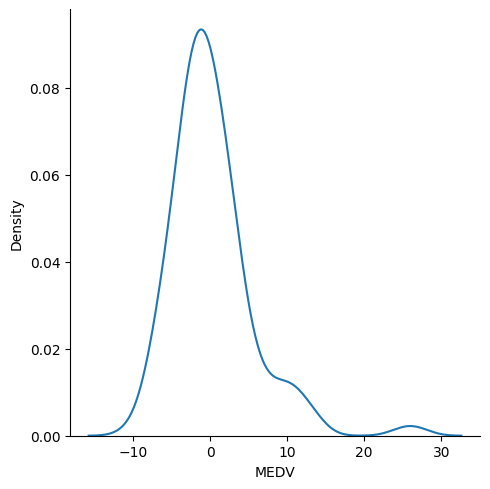

In [46]:
#comparing with target
sns.displot(y_test-reg_pre,kind='kde')

In [47]:
score=r2_score(y_test,reg_pre)
print(score)

0.6536649095128253
